In [1]:
%load_ext autoreload
%autoreload 2
    
from transformers import AutoModelForCausalLM, AutoTokenizer, BitsAndBytesConfig
from pylatexenc.latex2text import LatexNodes2Text
import os
import torch

from transformers import GenerationConfig

DEVICES = '3'
os.environ["CUDA_VISIBLE_DEVICES"] = DEVICES

/notebooks/strievich/itmo_practice/practice_env/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Tiktoken Tokenizer

In [2]:
import tiktoken
enc = tiktoken.get_encoding("cl100k_base")

texts = [
    "токенизатор",
    "Лучшая еда - это шавуха",
]

for s in texts:
    ids = enc.encode(s)
    tokens = [enc.decode([i]) for i in ids]

    print(f"\n=== '{s}' ===")
    print("token IDs:", ids)
    print("tokens   :", tokens)
    print("decoded  :", enc.decode(ids))


=== 'токенизатор' ===
token IDs: [1830, 15088, 9882, 9136, 58406]
tokens   : ['т', 'ок', 'ени', 'з', 'атор']
decoded  : токенизатор

=== 'Лучшая еда - это шавуха' ===
token IDs: [65014, 29471, 12426, 36497, 22918, 40590, 482, 68979, 55617, 18226, 3865, 10693, 1506]
tokens   : ['Л', 'уч', 'ш', 'ая', ' е', 'да', ' -', ' это', ' ш', 'ав', 'у', 'х', 'а']
decoded  : Лучшая еда - это шавуха


In [3]:
tokenizer_map = enc._mergeable_ranks
special_tokens = enc._special_tokens   

In [4]:
special_tokens

{'<|endoftext|>': 100257,
 '<|fim_prefix|>': 100258,
 '<|fim_middle|>': 100259,
 '<|fim_suffix|>': 100260,
 '<|endofprompt|>': 100276}

In [5]:
len(tokenizer_map)

100256

In [6]:
tokenizer_map

{b'!': 0,
 b'"': 1,
 b'#': 2,
 b'$': 3,
 b'%': 4,
 b'&': 5,
 b"'": 6,
 b'(': 7,
 b')': 8,
 b'*': 9,
 b'+': 10,
 b',': 11,
 b'-': 12,
 b'.': 13,
 b'/': 14,
 b'0': 15,
 b'1': 16,
 b'2': 17,
 b'3': 18,
 b'4': 19,
 b'5': 20,
 b'6': 21,
 b'7': 22,
 b'8': 23,
 b'9': 24,
 b':': 25,
 b';': 26,
 b'<': 27,
 b'=': 28,
 b'>': 29,
 b'?': 30,
 b'@': 31,
 b'A': 32,
 b'B': 33,
 b'C': 34,
 b'D': 35,
 b'E': 36,
 b'F': 37,
 b'G': 38,
 b'H': 39,
 b'I': 40,
 b'J': 41,
 b'K': 42,
 b'L': 43,
 b'M': 44,
 b'N': 45,
 b'O': 46,
 b'P': 47,
 b'Q': 48,
 b'R': 49,
 b'S': 50,
 b'T': 51,
 b'U': 52,
 b'V': 53,
 b'W': 54,
 b'X': 55,
 b'Y': 56,
 b'Z': 57,
 b'[': 58,
 b'\\': 59,
 b']': 60,
 b'^': 61,
 b'_': 62,
 b'`': 63,
 b'a': 64,
 b'b': 65,
 b'c': 66,
 b'd': 67,
 b'e': 68,
 b'f': 69,
 b'g': 70,
 b'h': 71,
 b'i': 72,
 b'j': 73,
 b'k': 74,
 b'l': 75,
 b'm': 76,
 b'n': 77,
 b'o': 78,
 b'p': 79,
 b'q': 80,
 b'r': 81,
 b's': 82,
 b't': 83,
 b'u': 84,
 b'v': 85,
 b'w': 86,
 b'x': 87,
 b'y': 88,
 b'z': 89,
 b'{': 90,
 b'|': 9

In [7]:
key = 'уч'.encode('utf-8')
key

b'\xd1\x83\xd1\x87'

In [8]:
tokenizer_map[key]

29471

## Загрузка модели с HF локально

In [ ]:
# отдельно создаем модель и соответствующий токенайзер

MODEL_NAME = "Qwen/Qwen2.5-1.5B-Instruct"
model_fp32 = AutoModelForCausalLM.from_pretrained(
        model_name,
        torch_dtype=torch.float32,
        device_map='auto',
        quantization_config=None
    )
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

In [11]:
model_fp32

Qwen2ForCausalLM(
  (model): Qwen2Model(
    (embed_tokens): Embedding(151936, 1536)
    (layers): ModuleList(
      (0-27): 28 x Qwen2DecoderLayer(
        (self_attn): Qwen2Attention(
          (q_proj): Linear(in_features=1536, out_features=1536, bias=True)
          (k_proj): Linear(in_features=1536, out_features=256, bias=True)
          (v_proj): Linear(in_features=1536, out_features=256, bias=True)
          (o_proj): Linear(in_features=1536, out_features=1536, bias=False)
        )
        (mlp): Qwen2MLP(
          (gate_proj): Linear(in_features=1536, out_features=8960, bias=False)
          (up_proj): Linear(in_features=1536, out_features=8960, bias=False)
          (down_proj): Linear(in_features=8960, out_features=1536, bias=False)
          (act_fn): SiLU()
        )
        (input_layernorm): Qwen2RMSNorm((1536,), eps=1e-06)
        (post_attention_layernorm): Qwen2RMSNorm((1536,), eps=1e-06)
      )
    )
    (norm): Qwen2RMSNorm((1536,), eps=1e-06)
    (rotary_emb): Qw

In [13]:
# конфиг модели
model_fp32.config

Qwen2Config {
  "architectures": [
    "Qwen2ForCausalLM"
  ],
  "attention_dropout": 0.0,
  "bos_token_id": 151643,
  "eos_token_id": 151645,
  "hidden_act": "silu",
  "hidden_size": 1536,
  "initializer_range": 0.02,
  "intermediate_size": 8960,
  "max_position_embeddings": 32768,
  "max_window_layers": 21,
  "model_type": "qwen2",
  "num_attention_heads": 12,
  "num_hidden_layers": 28,
  "num_key_value_heads": 2,
  "rms_norm_eps": 1e-06,
  "rope_scaling": null,
  "rope_theta": 1000000.0,
  "sliding_window": 32768,
  "tie_word_embeddings": true,
  "torch_dtype": "float32",
  "transformers_version": "4.52.4",
  "use_cache": true,
  "use_sliding_window": false,
  "vocab_size": 151936
}

In [18]:
tokenizer

Qwen2TokenizerFast(name_or_path='Qwen/Qwen2.5-1.5B-Instruct', vocab_size=151643, model_max_length=131072, is_fast=True, padding_side='right', truncation_side='right', special_tokens={'eos_token': '<|im_end|>', 'pad_token': '<|endoftext|>', 'additional_special_tokens': ['<|im_start|>', '<|im_end|>', '<|object_ref_start|>', '<|object_ref_end|>', '<|box_start|>', '<|box_end|>', '<|quad_start|>', '<|quad_end|>', '<|vision_start|>', '<|vision_end|>', '<|vision_pad|>', '<|image_pad|>', '<|video_pad|>']}, clean_up_tokenization_spaces=False, added_tokens_decoder={
	151643: AddedToken("<|endoftext|>", rstrip=False, lstrip=False, single_word=False, normalized=False, special=True),
	151644: AddedToken("<|im_start|>", rstrip=False, lstrip=False, single_word=False, normalized=False, special=True),
	151645: AddedToken("<|im_end|>", rstrip=False, lstrip=False, single_word=False, normalized=False, special=True),
	151646: AddedToken("<|object_ref_start|>", rstrip=False, lstrip=False, single_word=False,

In [69]:
def invoke(model, tokenizer, prompt, system_prompt=None, config=None):
    device = model.device
    if config is not None:
        model.generation_config = config

    messages = [
        {"role": "system", "content": system_prompt},
        {"role": "user", "content": prompt}
    ]

    # формирует входной промпт в виде текста и спец. токенов 
    text = tokenizer.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True
    )
    print(f'Input as a text:\n---\n{text}', end='---\n\n')

    # переводит (энкодит) входный текст в последовательность токенов (id токенов)
    model_inputs = tokenizer([text], padding=False, return_tensors="pt").to(device)
    print(f'Input as token ids:\n---\n{model_inputs}', end='\n---\n\n')

    # вызов модели (генерация)
    generated_ids = model.generate(
        **model_inputs,
        generation_config=config,
        max_new_tokens=2000,
        max_length=None,
        min_new_tokens=None
    )

    # оставляем только сгенерированные токены (обрезаем входные токены)
    generated_ids = [
        output_ids[len(input_ids):] for input_ids, output_ids in zip(model_inputs.input_ids, generated_ids)
    ]
    print(f'Output as token ids:\n---\n {generated_ids}', end='\n---\n\n')

    # переводит (декодирует) выходную последовательность индексов токенов в текст
    response = tokenizer.batch_decode(generated_ids, skip_special_tokens=False)[0]
    print(f'Output as text:\n---\n {response}', end='\n---')
    return response

In [38]:
system_prompt = 'You are math assistant. Solve the provided math problem step by step and put your final answer within \\boxed{}'
prompt = 'Реши квадратное уравнение: x**2 + 1 = 0'

output = invoke(model_fp32, tokenizer, prompt=prompt, system_prompt=system_prompt,)

Input as a text:
---
<|im_start|>system
You are math assistant. Solve the provided math problem step by step and put your final answer within \boxed{}<|im_end|>
<|im_start|>user
Реши квадратное уравнение: x**2 + 1 = 0<|im_end|>
<|im_start|>assistant
---

Input as token ids:
---
{'input_ids': tensor([[151644,   8948,    198,   2610,    525,   6888,  17847,     13,  63284,
            279,   3897,   6888,   3491,   3019,    553,   3019,    323,   2182,
            697,   1590,   4226,   2878,   1124,  79075,   6257, 151645,    198,
         151644,    872,    198,  33504,   1504,  29380,   7665,   5474,  22833,
          80559,  47050,  13932,  26988,   2108,  17175,     25,    856,    334,
             17,    488,    220,     16,    284,    220,     15, 151645,    198,
         151644,  77091,    198]], device='cuda:0'), 'attention_mask': tensor([[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
         1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 

### Поговорим немного о параметрах генерации

Самый простой способ выбрать следующий токен - выбрать токен с максимальной вероятностью, т.е. сделать argmax над выходом из модели. 
Такой метод называется `greedy sampling`

Однако этот подход не всегда хорош: он делает ответы детерминированными и лишает креативности.
Чтобы добавить разнообразие в генерацию, используются разные методы семплирования следующего токена:

0. `do_sample` - random_choice пропорционально вероятности: `idx = np.random.choice(token_ids, p=probs)`

1. `temperature` - перенормирует логиты следующим образом:
<div align="center">
  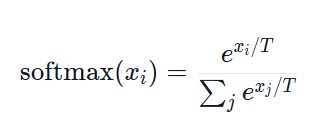
</div>

t > 1 - делает распределение вероятности более равномерным, повышая креативность ответов \
t < 1 - делает ответы более детерминированными \
t = 0 - равносильно greedy sampling(не всегда, но, например, в vllm это так)
<div align="center">
  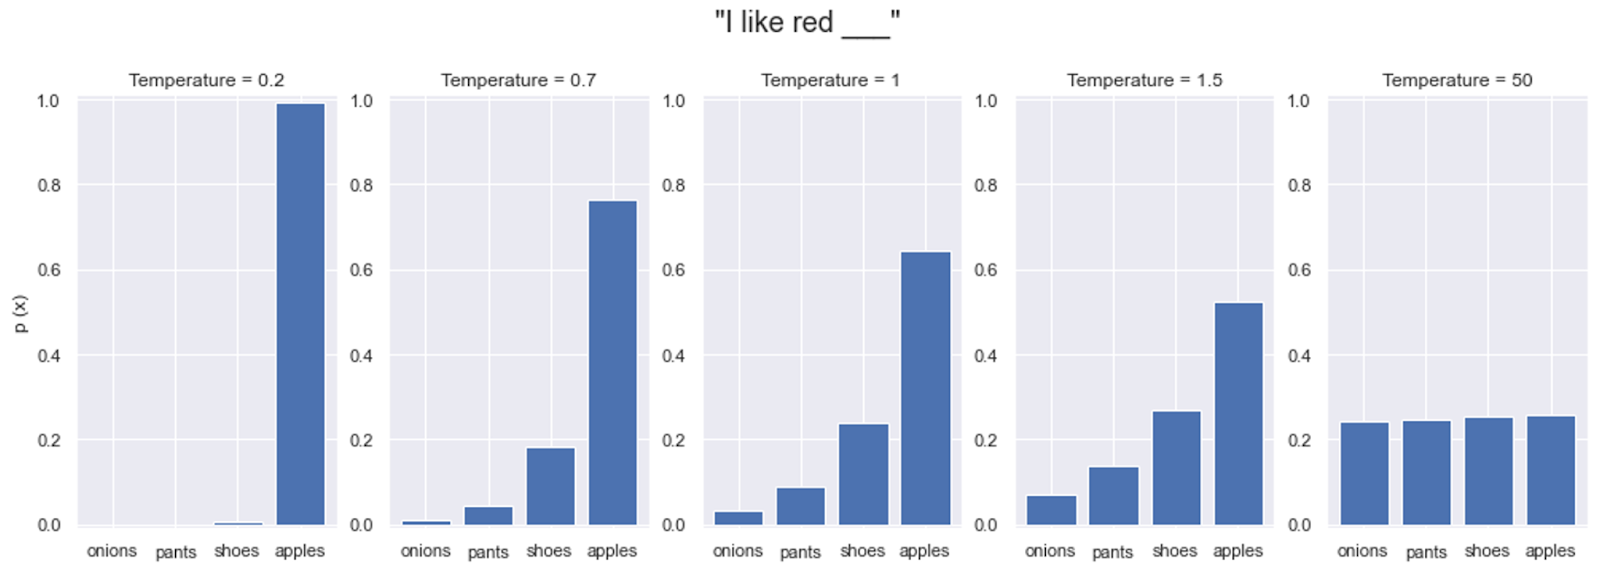
</div>

2. `beam search`:

    1) Держим num_beams лучших префиксов (лучший по log-правдоподобию)
    2) На каждом шаге, каждый beam расширяем всевозможными токенами (как правило, весь словарь V), собираем пулл beam-кандидатов
    3) Из пулла кандидатов снова выбираем num_beamns лучших префиксов и так далее, пока не упремся в <EOS> либо пока не сработает другой критерий остановки (например, max_new_tokens)
    4) В конце выбираем префикс с наибольшим скором log-правдоподобия
   
4. `top-k` - на каждом шаге оставляем только top k токенов по вероятности.

   Хотим больше креатива - повышаем k.
   Типичные значения - 20-40

6. `top-p` - оставляем наименьший набор токенов с суммарной вероятностью ≥ p.

    Хотим больше креатива - повышаем p.
    Типичные значения - 0.9-1
 
8. `max_new_tokens` - максимальное количество сгенерированных токенов

9. penalty paramaters: `length_penalty` - штраф за длину выхода, `repetition_penalt`y - штраф за повторы 

**Best practices**
1. Хотим детерминированность - do_sample = False
2. Хотим большей вариативности - do_sample = True, temperature = 0.5-1, можно добавить top_p или top_k
3. Хотим максимальную вариантивность - do_sample = True, temperature > 1, можно добавить top_p или top_k

In [71]:
config = GenerationConfig.from_pretrained("Qwen/Qwen2.5-1.5B-Instruct")

_ = config.update(
    temperature=1,
    top_p=0.9, top_k=20,
    do_sample=True,
    max_new_tokens=512,
    num_beams=1,
    #length_penalty,
    #repetition_penalty    
)

In [72]:
system_prompt = 'You are math assistant. Solve the provided math problem step by step and put your final answer within \\boxed{}'
prompt = 'Реши квадратное уравнение: x**2 + 1 = 0'

output = invoke(model_fp32, tokenizer, prompt=prompt, system_prompt=system_prompt, config=config)

Input as a text:
---
<|im_start|>system
You are math assistant. Solve the provided math problem step by step and put your final answer within \boxed{}<|im_end|>
<|im_start|>user
Реши квадратное уравнение: x**2 + 1 = 0<|im_end|>
<|im_start|>assistant
---

Input as token ids:
---
{'input_ids': tensor([[151644,   8948,    198,   2610,    525,   6888,  17847,     13,  63284,
            279,   3897,   6888,   3491,   3019,    553,   3019,    323,   2182,
            697,   1590,   4226,   2878,   1124,  79075,   6257, 151645,    198,
         151644,    872,    198,  33504,   1504,  29380,   7665,   5474,  22833,
          80559,  47050,  13932,  26988,   2108,  17175,     25,    856,    334,
             17,    488,    220,     16,    284,    220,     15, 151645,    198,
         151644,  77091,    198]], device='cuda:0'), 'attention_mask': tensor([[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
         1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 

https://huggingface.co/docs/transformers/v4.50.0/en/main_classes/text_generation#transformers.GenerationConfig \
Очень много разных параметров, отвечающих за генерацию моделью. По ссылке можно почитать подробнее о них

Поэкспериментируйте с различными параметрами генерации. Понаблюдайте, как изменяются ответы модели. Попробуйте также различные входные промпты. \
Сделайте выводы :)

## HF API

https://huggingface.co/docs/inference-providers/index

In [73]:
from huggingface_hub import InferenceClient

client = InferenceClient(
    provider="novita", # провайдер - сервер, на котором развернута модель
    api_key="", # ваш api токен, который надо получить на сайте hugging face
)

# создает OpenAI-совместимый эндпоинт chat_completions
completion = client.chat.completions.create(
    model="deepseek-ai/DeepSeek-R1",
    messages=[
        {
            "role": "user",
            "content": "Реши квадратное уравнение x ** 2= 1"
        }
    ],
)

print(completion.choices[0].message)

ChatCompletionOutputMessage(role='assistant', content='<think>\nХорошо, мне нужно решить квадратное уравнение x в квадрате равно 1. Давай начну с того, что вспомню, как решаются такие уравнения. Вообще, квадратное уравнение имеет вид ax² + bx + c = 0. В нашем случае уравнение x² = 1, поэтому я могу переписать его в стандартной форме, вычтя 1 из обеих частей: x² - 1 = 0. Теперь видно, что a = 1, b = 0, c = -1.\n\nНо, возможно, есть более простой способ решить это уравнение, не используя стандартную формулу для квадратных уравнений. Поскольку уравнение выглядит довольно простым, можно попробовать перенести все слагаемые в одну сторону и разложить на множители, если это возможно.\n\nИтак, x² - 1 = 0. Замечаю, что это разность квадратов. Формула разности квадратов: a² - b² = (a - b)(a + b). Применим ее здесь: x² - 1² = (x - 1)(x + 1) = 0.\n\nТеперь, согласно свойству нулевого произведения, если произведение двух множителей равно нулю, то хотя бы один из них должен быть равен нулю. Поэтому 

## VLLM

### Offline inference

Для offline инференса модель можно запустить напрямую в коде, без поднятия сервера. Это делается аналогично работе через Hugging Face, с помощью класса `LLM` - https://qwen.readthedocs.io/en/latest/deployment/vllm.html

### Online inference

В это случае вы разворачиваете OpenAI-совместимый сервер, к которому можно обращаться по стандартным эндпоинтам (`/v1/chat/completions`, `/v1/completions`, и тд). \

**Способы запуска:**

1. Можно запустить через docker контейнер:

In [2]:
!cat ./run_vllm_docker_1.sh

MODEL_NAME="Qwen/Qwen2.5-1.5B-Instruct-AWQ"
IMAGE_NAME="vllm/vllm-openai:latest"
PORT=11001
HUGGINGFACE_TOKEN=""
CACHE_DIR="$HOME/.cache/huggingface"
CUDA_VISIBLE_DEVICES=3

docker run --gpus all \
    -v ${CACHE_DIR}:/root/.cache/huggingface \
    --env "HUGGING_FACE_HUB_TOKEN=${HUGGINGFACE_TOKEN}" \
    --env "CUDA_VISIBLE_DEVICES=${CUDA_VISIBLE_DEVICES}" \
    -p ${PORT}:8000 \
    --ipc=host \
    ${IMAGE_NAME} \
    --model ${MODEL_NAME} \
    --enable-auto-tool-choice \
    --tool-call-parser=hermes \
    --gpu-memory-utilization 0.7


2. Если вы работаете в google colab, то запустить можно следующим образом:

In [ ]:
import os, pathlib

HF_TOKEN = "" # ваш HF token

cache_dir = pathlib.Path.home()/".cache"/"huggingface"
cache_dir.mkdir(parents=True, exist_ok=True)

os.environ["HF_HOME"] = str(cache_dir)
# vLLM читает HF_TOKEN; сам huggingface_hub читает HUGGING_FACE_HUB_TOKEN — установим оба
os.environ["HF_TOKEN"] = HF_TOKEN
os.environ["HUGGING_FACE_HUB_TOKEN"] = HF_TOKEN

!nohup python -m vllm.entrypoints.openai.api_server \
  --model "Qwen/Qwen2.5-7B-Instruct-AWQ" \
  --host 0.0.0.0 \
  --port 11001 \
  --dtype auto \
  --gpu-memory-utilization 0.90 \
  --quantization awq \
  --api-key "token-abc123" \
  --enable-auto-tool-choice \
  --tool-call-parser hermes

3. Либо через `vllm serve`:

In [ ]:
!vllm serve ... (те же самые параметры, что и выше)

Затем мы создаём клиента, который обращается к серверу через OpenAI-совместимый эндпоинт `/v1/chat/completions`. Для этого используется класс `OpenAI`

In [188]:
from openai import OpenAI

openai_api_key = "empty" # ваш ключ, с которым вы развернули свой vllm server

vllm_client = OpenAI(
    api_key=openai_api_key,
    base_url="" # url с развернутым сервером
)

In [182]:
chat_completion = client.chat.completions.create(
    messages=[{
        "role": "system",
        "content": "You are a helpful assistant."
    }, {
        "role": "user",
        "content": "Реши квадратное уравнение: x**2 + 1 = 0."
    }],
    model="Qwen/Qwen2.5-1.5B-Instruct-AWQ",
    temperature=0,
    max_completion_tokens=2048, 
    stream=True
)

Если без стриминга, то аутпут достается так

In [ ]:
chat_completion.choices[0].message.content

Если запускать генерацию модели в стриминге (`stream = True`):

In [123]:
import time

output_text = ""
first_token_time = None
start_total = time.time()

for chunk in chat_completion:
    content = chunk.choices[0].delta.content or ""
    print(content, end='|', flush=True)
    output_text += content

К|он|ечно|!| Д|ав|айте| реш|им| это| к|в|ад|рат|ное| у|рав|н|ение| \(|x|^|2| +| |1| =| |0|\|).

|1|.| У|м|н|ож|аем| об|е| части| у|рав|н|ения| на| -|1| для| из|бав|ления| от| |1|:
|  | \|[
|  | -|x|^|2| -| |1| =| |0|
|  | \|]
|  | \|[
|  | -|x|^|2| =| |1|
|  | \|]

|2|.| Теперь| у|м|н|ож|аем| об|е| части| у|рав|н|ения| на| -|1| снова|:
|  | \|[
|  | x|^|2| =| -|1|
|  | \|]

|3|.| Р|еш|аем| у|рав|н|ение| \(|x|^|2| =| -|1|\|).| Это| у|рав|н|ение| имеет| два| решения|:
|  | \|[
|  | x| =| \|pm| \|sqrt|{-|1|}
|  | \|]
|  | \|[
|  | x| =| \|pm| i|
|  | \|]
|  | где| \(|i|\)| -| это| комплекс|ный| м|ним|ый| чис|ла|.

|Т|ак|им| образом|,| решения| у|рав|н|ения| \(|x|^|2| +| |1| =| |0|\)| -| это| \(|x| =| i|\)| и| \(|x| =| -|i|\|).||

Полезные ссылки:

1. https://docs.vllm.ai/en/latest/serving/openai_compatible_server.html
2. Ссылка, где объясняется часть оптимизаций: https://docs.vllm.ai/en/latest/performance/optimization.html
3. Ссылка про distributed inference: https://docs.vllm.ai/en/v0.5.2/serving/distributed_serving.html

## Загрузка модели через TGI

Запускаются похожим образом, что и в vllm - https://huggingface.co/docs/text-generation-inference/index

In [ ]:
tgi_client = OpenAI(
    api_key=openai_api_key,
    base_url=""
)

## ollama (llama.cpp) - см. ноутбук с дз